# Eksperimen: Ablasi 10 Fitur Trik DDS

## Pertanyaan
Apakah 10 fitur jumlah trik Double-Dummy (`ns_dd_*`, `ew_dd_*`) meningkatkan kinerja RandomForest, XGBoost, dan LightGBM dibanding 164 fitur kanonik tangan/auction?

## Definisi eksperimen
- **Tanpa fitur DDS:** 164 fitur kanonik dari `data/processed_no_dds/`.
- **Dengan fitur DDS:** fitur kanonik yang sama ditambah 10 kolom trik DD dari cache v4.
- Kedua kondisi memakai baris, label, dan split train/validation/test yang sama.
- Label `matches_par_contract` tetap dihitung menggunakan DDS v4: kecocokan kontrak aktual dengan salah satu kontrak par berdasarkan level, strain, status double/redouble, dan sisi declarer. Karena itu eksperimen ini mengukur kontribusi fitur trik DD, bukan menghilangkan DDS dari definisi label.
- Hyperparameter mengikuti `configs/config.yaml`. Tidak ada tuning. Test set dievaluasi setelah seluruh model ditentukan.

Notebook ini menulis ringkasan ke folder `outputs/` di samping notebook. Dataset resmi dan model resmi tidak ditimpa.

In [1]:
from pathlib import Path
import json
import sys
import time

import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)

# Temukan root repo dari working directory kernel.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in _candidates if (p / "configs/config.yaml").exists() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.models import RFModel, XGBModel, LGBMModel

DATA_DIR = ROOT / "data" / "processed_no_dds"
DDS_CACHE = ROOT / "data" / "combined_dds_cache_v4.csv"
EXP_DIR = ROOT / "experiments" / "2026-10-16" / "no_dds_feature_ablation"
OUT_DIR = EXP_DIR / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = yaml.safe_load((ROOT / "configs/config.yaml").read_text(encoding="utf-8"))

assert DATA_DIR.exists(), f"Dataset belum ada: {DATA_DIR}. Jalankan scripts/build_dataset_no_dds.py dahulu."
assert DDS_CACHE.exists(), f"Cache label/features v4 tidak ditemukan: {DDS_CACHE}"
print(f"Repo      : {ROOT}")
print(f"Dataset   : {DATA_DIR}")
print(f"DDS cache : {DDS_CACHE}")

Repo      : D:\Bridge-Prediction
Dataset   : D:\Bridge-Prediction\data\processed_no_dds
DDS cache : D:\Bridge-Prediction\data\combined_dds_cache_v4.csv


## 1. Muat split yang sama untuk kedua kondisi

Ambil 10 fitur trik dari cache v4, lalu gabungkan berdasarkan identitas board. `validate='many_to_one'` menjaga agar penggabungan tidak menggandakan baris.

In [2]:
KEYS = ["_source_file", "_room", "_board_number"]
feature_cols = json.loads((DATA_DIR / "feature_columns.json").read_text(encoding="utf-8"))
DDS_TRICK_COLS = [f"{side}_dd_{strain}" for strain in ["S", "H", "D", "C", "N"] for side in ["ns", "ew"]]
assert len(feature_cols) == 164, f"Ekspektasi 164 fitur kanonik; ditemukan {len(feature_cols)}"
assert not set(DDS_TRICK_COLS) & set(feature_cols)

dds = pd.read_csv(DDS_CACHE, keep_default_na=False, dtype={k: str for k in KEYS})
dds = dds[KEYS + DDS_TRICK_COLS]
assert not dds.duplicated(KEYS).any(), "Cache DDS v4 memiliki kunci board duplikat"

splits = {}
for split_name in ["train", "val", "test"]:
    frame = pd.read_csv(DATA_DIR / f"{split_name}.csv", keep_default_na=False, dtype={k: str for k in KEYS})
    merged = frame.merge(dds, on=KEYS, how="left", validate="many_to_one")
    missing = int(merged[DDS_TRICK_COLS].isna().any(axis=1).sum())
    assert missing == 0, f"{split_name}: {missing} baris tidak mendapat fitur DDS"
    splits[split_name] = merged

print("Fitur tanpa DDS:", len(feature_cols))
print("Fitur dengan DDS:", len(feature_cols) + len(DDS_TRICK_COLS))
print("Jumlah baris:", {k: len(v) for k, v in splits.items()})
print("Positif train/val/test:", {k: round(float(v.matches_par_contract.mean()), 4) for k, v in splits.items()})
assert all("_deal_key" in frame for frame in splits.values()), "Split tidak menggunakan identitas deal kanonik"

Fitur tanpa DDS: 164
Fitur dengan DDS: 174
Jumlah baris: {'train': 35161, 'val': 7534, 'test': 7532}
Positif train/val/test: {'train': 0.2456, 'val': 0.2457, 'test': 0.2455}


## 2. Siapkan model dan metrik

Metrik utama adalah F1 macro karena ketidakseimbangan kelas. F1 positif, ROC-AUC, PR-AUC, accuracy, dan F1 weighted ikut dilaporkan.

In [3]:
MODEL_FACTORIES = {
    "RandomForest": lambda: RFModel(**CONFIG["models"]["random_forest"]),
    "XGBoost": lambda: XGBModel(**CONFIG["models"]["xgboost"]),
    "LightGBM": lambda: LGBMModel(**CONFIG["models"]["lightgbm"]),
}
FEATURE_SETS = {
    "tanpa_dds_164": feature_cols,
    "dengan_dds_174": feature_cols + DDS_TRICK_COLS,
}

def score_binary(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "precision_positive": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall_positive": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_positive": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba[:, 1]),
        "average_precision": average_precision_score(y_true, y_proba[:, 1]),
    }

## 3. Training dan evaluasi validation

Semua enam kombinasi memakai seed dan konfigurasi proyek. Validation dipakai untuk membaca selisih fitur; tidak ada pencarian hyperparameter.

In [4]:
fitted = {}
val_rows = []

for model_name, make_model in MODEL_FACTORIES.items():
    fitted[model_name] = {}
    for feature_name, cols in FEATURE_SETS.items():
        model = make_model()
        train = splits["train"]
        val = splits["val"]
        t0 = time.perf_counter()
        model.fit(train[cols].to_numpy(dtype=np.float32), train["label"].to_numpy())
        fit_seconds = time.perf_counter() - t0
        fitted[model_name][feature_name] = model
        pred = model.predict(val[cols].to_numpy(dtype=np.float32))
        proba = model.predict_proba(val[cols].to_numpy(dtype=np.float32))
        row = {"model": model_name, "feature_set": feature_name, "n_features": len(cols), "fit_seconds": fit_seconds}
        row.update(score_binary(val["label"].to_numpy(), pred, proba))
        val_rows.append(row)

val_results = pd.DataFrame(val_rows).sort_values(["model", "feature_set"]).reset_index(drop=True)
val_results

,model,feature_set,n_features,fit_seconds,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,precision_positive,recall_positive,f1_positive,roc_auc,average_precision
0,LightGBM,dengan_dds_174,174,2.462734,0.792275,0.722070,0.734991,0.727879,0.795209,0.570862,0.622366,0.595503,0.812112,0.633183
1,LightGBM,tanpa_dds_164,164,2.300720,0.721264,0.637286,0.650946,0.642518,0.727855,0.442012,0.512696,0.474737,0.712560,0.459019
2,RandomForest,dengan_dds_174,174,10.485054,0.803823,0.738860,0.690553,0.707461,0.792858,0.637233,0.467855,0.539564,0.787990,0.609439
3,RandomForest,tanpa_dds_164,164,8.644110,0.765331,0.671130,0.616952,0.629475,0.743591,0.537021,0.325230,0.405114,0.714777,0.470365
4,XGBoost,dengan_dds_174,174,3.929595,0.811654,0.765848,0.674797,0.698694,0.792529,0.701869,0.405727,0.514207,0.795729,0.607083
5,XGBoost,tanpa_dds_164,164,3.904983,0.771171,0.699360,0.572920,0.573076,0.720991,0.615245,0.183144,0.282265,0.711510,0.466512


## 4. Evaluasi final pada test set

Model dan konfigurasi sudah ditetapkan sebelum tahap ini. Test dipakai sekali untuk membandingkan enam hasil final.

In [5]:
test_rows = []
test = splits["test"]
y_test = test["label"].to_numpy()
for model_name, by_features in fitted.items():
    for feature_name, model in by_features.items():
        cols = FEATURE_SETS[feature_name]
        X_test = test[cols].to_numpy(dtype=np.float32)
        pred = model.predict(X_test)
        proba = model.predict_proba(X_test)
        row = {"model": model_name, "feature_set": feature_name, "n_features": len(cols)}
        row.update(score_binary(y_test, pred, proba))
        test_rows.append(row)

test_results = pd.DataFrame(test_rows).sort_values(["model", "feature_set"]).reset_index(drop=True)
test_results

,model,feature_set,n_features,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,precision_positive,recall_positive,f1_positive,roc_auc,average_precision
0,LightGBM,dengan_dds_174,174,0.791556,0.722042,0.739273,0.729482,0.795444,0.567229,0.636560,0.599898,0.815337,0.628482
1,LightGBM,tanpa_dds_164,164,0.714020,0.631225,0.646843,0.636743,0.722028,0.430964,0.514873,0.469197,0.704593,0.418000
2,RandomForest,dengan_dds_174,174,0.803240,0.736716,0.693926,0.709537,0.793514,0.630605,0.479178,0.544561,0.781237,0.588827
3,RandomForest,tanpa_dds_164,164,0.750000,0.639069,0.591510,0.599936,0.724659,0.484112,0.280151,0.354916,0.705061,0.435593
4,XGBoost,dengan_dds_174,174,0.808948,0.759603,0.671622,0.694745,0.789787,0.690520,0.401839,0.508034,0.792074,0.594637
5,XGBoost,tanpa_dds_164,164,0.759958,0.658200,0.553229,0.544532,0.703980,0.540755,0.147107,0.231293,0.708605,0.438595


## 5. Selisih berpasangan dan simpan hasil

Delta positif berarti skor membaik ketika 10 fitur trik DD ditambahkan. Prioritas interpretasi tetap F1 macro; periksa pula metrik positif agar perubahan pada kelas target terlihat.

In [6]:
METRICS = ["accuracy", "f1_macro", "f1_weighted", "f1_positive", "roc_auc", "average_precision"]
def paired_delta(results):
    wide = results.pivot(index="model", columns="feature_set", values=METRICS)
    rows = []
    for model_name in wide.index:
        row = {"model": model_name}
        for metric in METRICS:
            row[f"{metric}_without_minus_with"] = (
                wide.loc[model_name, (metric, "tanpa_dds_164")]
                - wide.loc[model_name, (metric, "dengan_dds_174")]
            )
        rows.append(row)
    return pd.DataFrame(rows)

val_delta = paired_delta(val_results)
test_delta = paired_delta(test_results)
val_results.to_csv(OUT_DIR / "validation_comparison.csv", index=False)
test_results.to_csv(OUT_DIR / "test_comparison.csv", index=False)
val_delta.to_csv(OUT_DIR / "validation_delta_no_dds_minus_dds.csv", index=False)
test_delta.to_csv(OUT_DIR / "test_delta_no_dds_minus_dds.csv", index=False)
summary = {
    "dataset": {
        "rows": sum(len(splits[s]) for s in ["train", "val", "test"]),
        "train": len(splits["train"]), "val": len(splits["val"]), "test": len(splits["test"]),
        "features_without_dds": len(feature_cols), "features_with_dds": len(feature_cols) + len(DDS_TRICK_COLS),
        "positive_rate_full": float(sum(splits[s]["matches_par_contract"].sum() for s in splits) / sum(len(splits[s]) for s in splits)),
        "label_definition": "actual contract matches any DDS par contract by level, strain, doubling, and declarer side",
    },
    "validation": val_results.to_dict(orient="records"),
    "test": test_results.to_dict(orient="records"),
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Validation delta (tanpa DDS - dengan DDS), pp untuk F1 macro:")
print((val_delta.set_index("model")["f1_macro_without_minus_with"] * 100).round(2))
print("Test delta (tanpa DDS - dengan DDS), pp untuk F1 macro:")
print((test_delta.set_index("model")["f1_macro_without_minus_with"] * 100).round(2))
print(f"\nHasil tersimpan di {OUT_DIR}")

Validation delta (tanpa DDS - dengan DDS), pp untuk F1 macro:
model
LightGBM        -8.54
RandomForest    -7.80
XGBoost        -12.56
Name: f1_macro_without_minus_with, dtype: float64
Test delta (tanpa DDS - dengan DDS), pp untuk F1 macro:
model
LightGBM        -9.27
RandomForest   -10.96
XGBoost        -15.02
Name: f1_macro_without_minus_with, dtype: float64

Hasil tersimpan di D:\Bridge-Prediction\experiments\2026-10-16\no_dds_feature_ablation\outputs


## 6. Evaluasi rinci kandidat terpilih

Pilih kandidat dengan F1 macro validation tertinggi, lalu tampilkan classification report dan confusion matrix test. Pemilihan hanya memakai validation; seluruh konfigurasi model sudah ditetapkan sebelumnya.

Dipilih dari validation: LightGBM / dengan_dds_174
                     precision    recall  f1-score   support

Tidak cocok par (0)     0.8769    0.8420    0.8591      5683
      Cocok par (1)     0.5672    0.6366    0.5999      1849

           accuracy                         0.7916      7532
          macro avg     0.7220    0.7393    0.7295      7532
       weighted avg     0.8008    0.7916    0.7954      7532



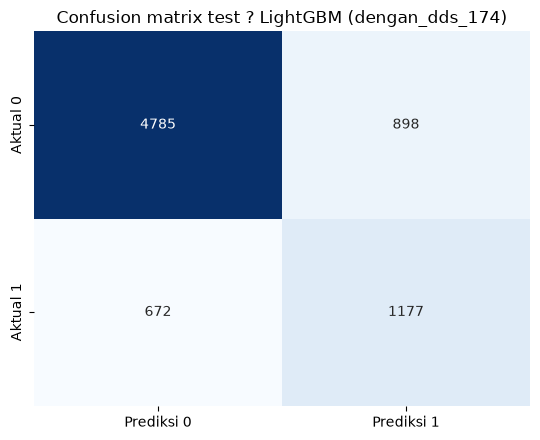

,Prediksi 0,Prediksi 1
Aktual 0,4785,898
Aktual 1,672,1177


In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

best_val_row = val_results.loc[val_results["average_precision"].idxmax()]
best_model_name = best_val_row["model"]
best_feature_name = best_val_row["feature_set"]
best_model = fitted[best_model_name][best_feature_name]
best_cols = FEATURE_SETS[best_feature_name]
X_test_best = test[best_cols].to_numpy(dtype=np.float32)
y_pred_best = best_model.predict(X_test_best)
y_proba_best = best_model.predict_proba(X_test_best)
print(f"Dipilih dari validation: {best_model_name} / {best_feature_name}")
print(classification_report(y_test, y_pred_best, target_names=["Tidak cocok par (0)", "Cocok par (1)"], digits=4, zero_division=0))

cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["Aktual 0", "Aktual 1"], columns=["Prediksi 0", "Prediksi 1"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title(f"Confusion matrix test ? {best_model_name} ({best_feature_name})")
plt.tight_layout()
fig.savefig(OUT_DIR / "best_model_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
cm_df

## 7. Analisis SHAP

Tree SHAP dihitung untuk 100 sampel test yang sama pada keenam model. Untuk RF digunakan mode aproksimasi Saabas karena perhitungan exact melampaui batas waktu praktis; XGBoost dan LightGBM memakai SHAP exact. Grafik dan tabel memakai `mean(|SHAP value|)` untuk kelas positif. Nilai ini merangkum seberapa besar fitur menggeser output model; ini ukuran kontribusi prediksi, bukan hubungan sebab-akibat. Bandingkan fitur DDS hanya di dalam model yang sama karena skala output SHAP dapat berbeda antar-algoritma dan metode RF aproksimasi tidak identik dengan Tree SHAP exact.

In [8]:
import shap

SHAP_SAMPLE_SIZE = min(100, len(test))
rng = np.random.RandomState(42)
shap_positions = np.sort(rng.choice(len(test), size=SHAP_SAMPLE_SIZE, replace=False))
shap_rows = []

def positive_class_shap(model, X):
    approximate = isinstance(model, RFModel)
    explainer = shap.TreeExplainer(model.clf)
    raw = explainer.shap_values(X, approximate=approximate)
    if isinstance(raw, list):
        values = np.asarray(raw[1])
    else:
        values = np.asarray(raw)
        if values.ndim == 3:
            if values.shape[-1] == 2:
                values = values[:, :, 1]
            elif values.shape[0] == 2:
                values = values[1]
    if values.ndim != 2 or values.shape[1] != X.shape[1]:
        raise ValueError(f"Bentuk SHAP tidak dikenali: {values.shape}; X={X.shape}")
    return values

for model_name, by_features in fitted.items():
    for feature_name, model in by_features.items():
        cols = FEATURE_SETS[feature_name]
        X_shap = test.iloc[shap_positions][cols].to_numpy(dtype=np.float32)
        method = "Saabas approx" if isinstance(model, RFModel) else "Tree SHAP exact"
        print(f"SHAP {model_name} / {feature_name} ({len(X_shap)} sampel; {method})...")
        sv = positive_class_shap(model, X_shap)
        importance = np.abs(sv).mean(axis=0)
        shap_rows.extend(
            {"model": model_name, "feature_set": feature_name, "feature": col, "mean_abs_shap": float(value)}
            for col, value in zip(cols, importance)
        )

shap_importance = pd.DataFrame(shap_rows)
shap_importance.to_csv(OUT_DIR / "shap_mean_absolute_importance.csv", index=False)
shap_importance.sort_values("mean_abs_shap", ascending=False).groupby(["model", "feature_set"]).head(10)

SHAP RandomForest / tanpa_dds_164 (100 sampel; Saabas approx)...


SHAP RandomForest / dengan_dds_174 (100 sampel; Saabas approx)...


SHAP XGBoost / tanpa_dds_164 (100 sampel; Tree SHAP exact)...


SHAP XGBoost / dengan_dds_174 (100 sampel; Tree SHAP exact)...


SHAP LightGBM / tanpa_dds_164 (100 sampel; Tree SHAP exact)...


D:\Bridge-Prediction\.venv\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP LightGBM / dengan_dds_174 (100 sampel; Tree SHAP exact)...


,model,feature_set,feature,mean_abs_shap
434,XGBoost,tanpa_dds_164,ns_hcp,0.338360
772,LightGBM,tanpa_dds_164,ns_hcp,0.300115
598,XGBoost,dengan_dds_174,ns_hcp,0.210444
936,LightGBM,dengan_dds_174,ns_hcp,0.197697
1013,LightGBM,dengan_dds_174,ew_dd_N,0.164506
675,XGBoost,dengan_dds_174,ew_dd_N,0.150747
667,XGBoost,dengan_dds_174,ew_dd_S,0.131975
1012,LightGBM,dengan_dds_174,ns_dd_N,0.124740
674,XGBoost,dengan_dds_174,ns_dd_N,0.123303
1005,LightGBM,dengan_dds_174,ew_dd_S,0.121583


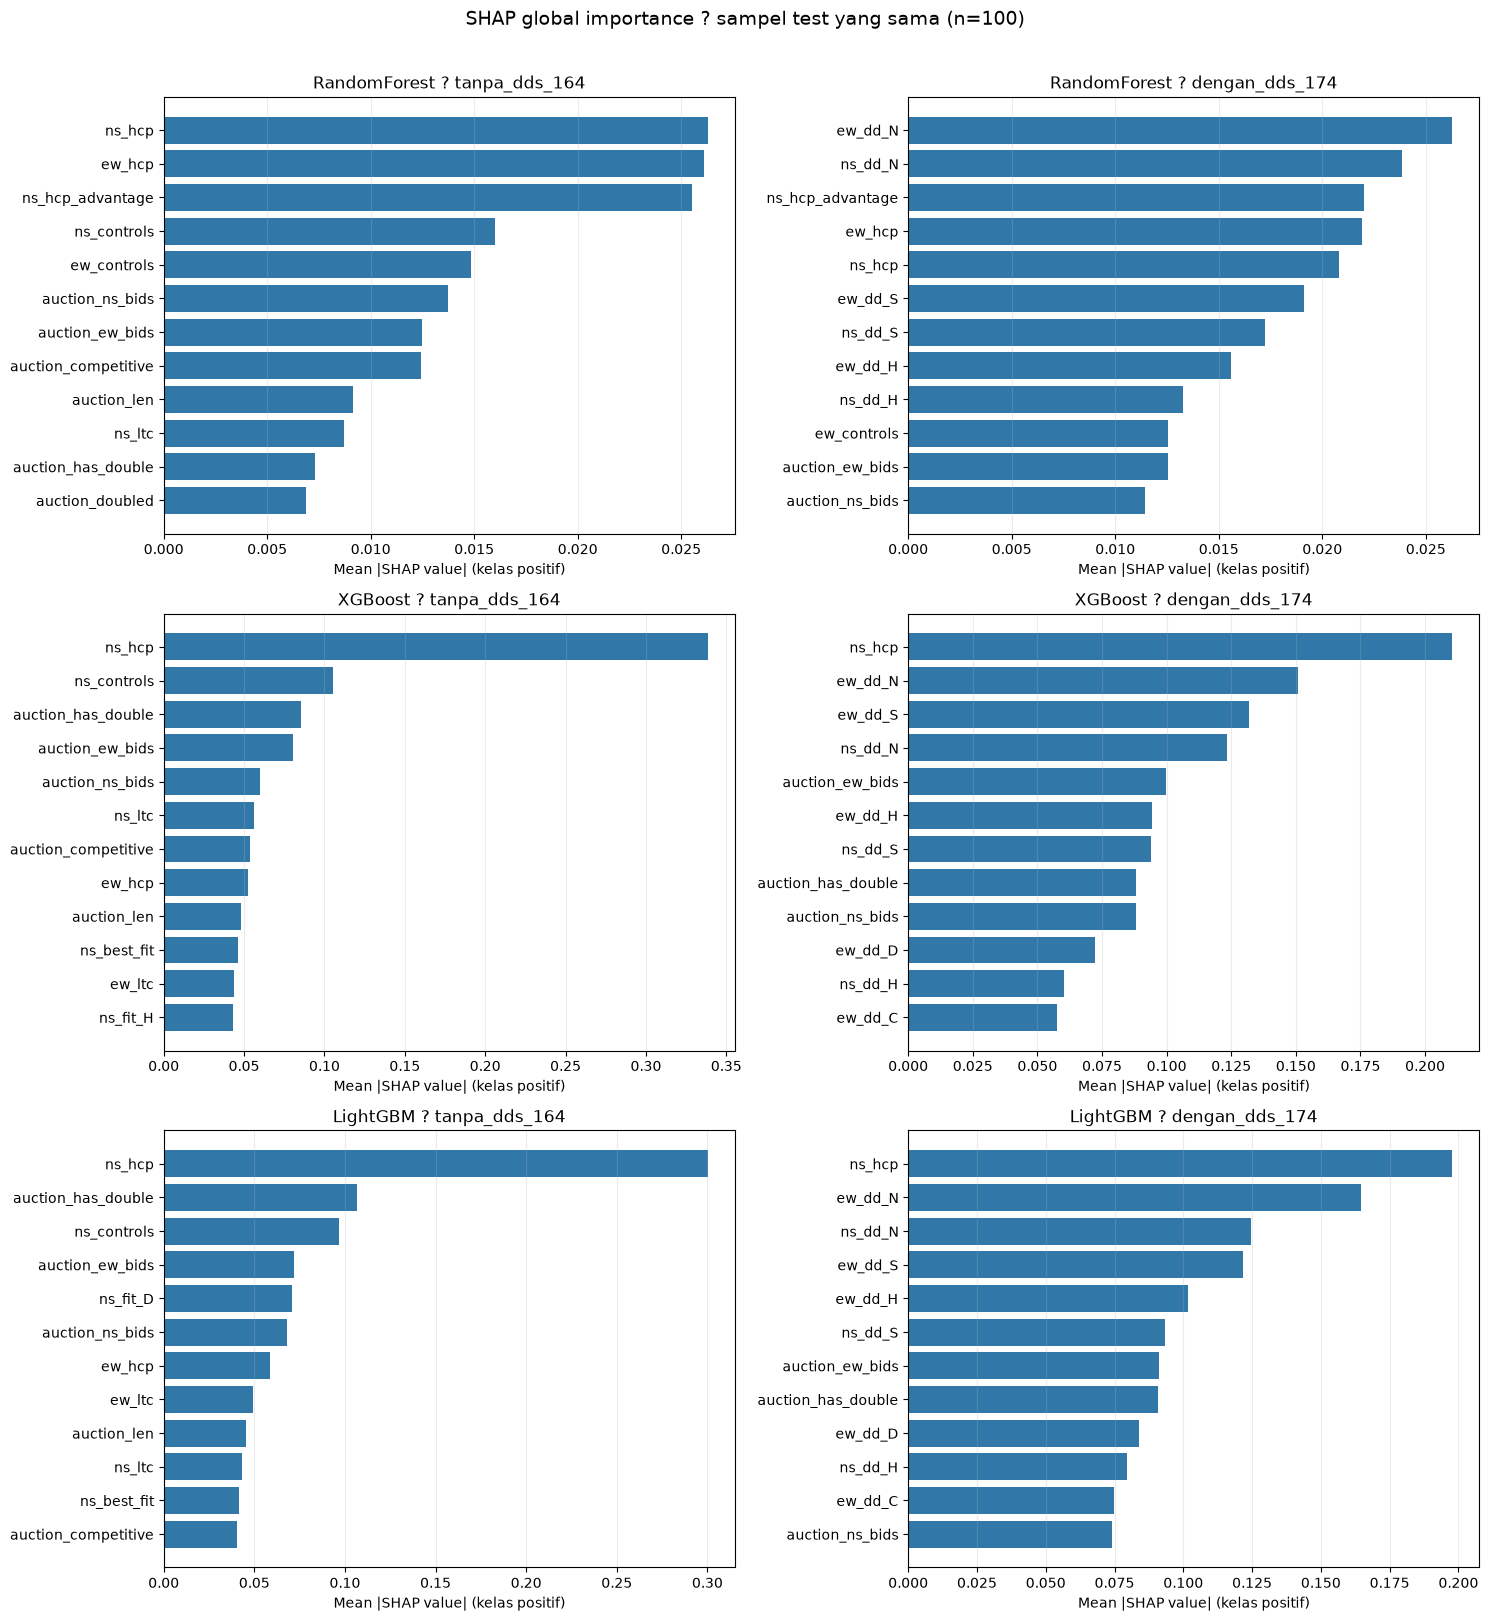

,model,feature_set,dds_features_in_top10,top10_mean_abs_shap_sum
0,LightGBM,dengan_dds_174,7,1.149061
1,LightGBM,tanpa_dds_164,0,0.910264
2,RandomForest,dengan_dds_174,6,0.192650
3,RandomForest,tanpa_dds_164,0,0.165255
4,XGBoost,dengan_dds_174,6,1.152990
5,XGBoost,tanpa_dds_164,0,0.925929


In [9]:
# Panel per algoritma: top 12 fitur pada model tanpa DDS dan dengan DDS.
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
for row_idx, model_name in enumerate(MODEL_FACTORIES):
    for col_idx, feature_name in enumerate(FEATURE_SETS):
        ax = axes[row_idx, col_idx]
        part = shap_importance[
            (shap_importance["model"] == model_name)
            & (shap_importance["feature_set"] == feature_name)
        ].nlargest(12, "mean_abs_shap").sort_values("mean_abs_shap")
        ax.barh(part["feature"], part["mean_abs_shap"], color="#3178a8")
        ax.set_title(f"{model_name} ? {feature_name}")
        ax.set_xlabel("Mean |SHAP value| (kelas positif)")
        ax.grid(axis="x", alpha=0.25)
fig.suptitle("SHAP global importance ? sampel test yang sama (n=100)", y=1.01, fontsize=14)
fig.tight_layout()
fig.savefig(OUT_DIR / "shap_top_features.png", dpi=160, bbox_inches="tight")
plt.show()

# Ringkasan apakah fitur DDS masuk ke top 10 dan kontribusi relatif dalam tiap model.
shap_top10 = shap_importance.sort_values("mean_abs_shap", ascending=False).groupby(["model", "feature_set"]).head(10)
shap_dd_summary = (
    shap_top10.assign(is_dds=lambda d: d["feature"].isin(DDS_TRICK_COLS))
    .groupby(["model", "feature_set"], as_index=False)
    .agg(dds_features_in_top10=("is_dds", "sum"), top10_mean_abs_shap_sum=("mean_abs_shap", "sum"))
)
shap_dd_summary